In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import tarfile
import os
import missingno as msno
import random
from sklearn.preprocessing import StandardScaler

In [3]:
file_path = '../data/data_new.csv'
data = pd.read_csv(file_path, sep=';')
data.head()

,chanvre 5,chanvre 15,bambou 5,bambou 15,lin 5,lin 6,lin 15,miscanthus 5,miscanthus 15,ch.antif.,...,Days,Slump (mm),Air occluded (%),Volumic mass (kg/m3),FS (Mpa),CS (Mpa),Aspect ratio (L/D) soft fibers,Aspect ratio (L/D) rigid fibers,Absorption coefficient t=2880s soft fibers,Absorption coefficient t=2880s rigid fibers
0,"0,4",0,0,0,0,0,0,0,0,0,...,1,430,3.7,2.2287,2.79,11.36,154,0,135.27,0
1,0,"0,4",0,0,0,0,0,0,0,0,...,1,455,3.6,2.2198,3.13,10,308,0,135.47,0
2,0,0,"0,4",0,0,0,0,0,0,0,...,1,450,3.2,2.2366,2.43,8.69,0,17,0.00,98.93
3,0,0,0,"0,4",0,0,0,0,0,0,...,1,450,3.3,2.2312,2.82,9.17,0,33,0.00,89.7
4,0,0,0,0,"0,4",0,0,0,0,0,...,1,417.5,3.6,2.2117,2.56,7.11,167,0,155.27,0


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 384 entries, 0 to 383
Data columns (total 21 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   chanvre 5                                    384 non-null    str    
 1   chanvre 15                                   384 non-null    str    
 2   bambou 5                                     384 non-null    str    
 3   bambou 15                                    384 non-null    str    
 4   lin 5                                        384 non-null    str    
 5   lin 6                                        384 non-null    str    
 6   lin 15                                       384 non-null    str    
 7   miscanthus 5                                 384 non-null    str    
 8   miscanthus 15                                384 non-null    str    
 9   ch.antif.                                    384 non-null    str    
 10  ch.strux     

In [5]:
data.describe()

,Days,Aspect ratio (L/D) soft fibers,Aspect ratio (L/D) rigid fibers,Absorption coefficient t=2880s soft fibers
count,384.000000,384.00000,384.000000,384.000000
mean,31.500000,163.75000,36.864583,87.281667
std,35.277342,167.65232,77.673834,71.146628
min,1.000000,0.00000,0.000000,0.000000
25%,5.500000,0.00000,0.000000,0.000000
50%,17.500000,154.00000,23.000000,135.270000
75%,43.500000,167.00000,33.000000,155.270000
max,90.000000,636.00000,333.000000,155.270000


# 2. Data Cleaning

## 2.1 Missing Values

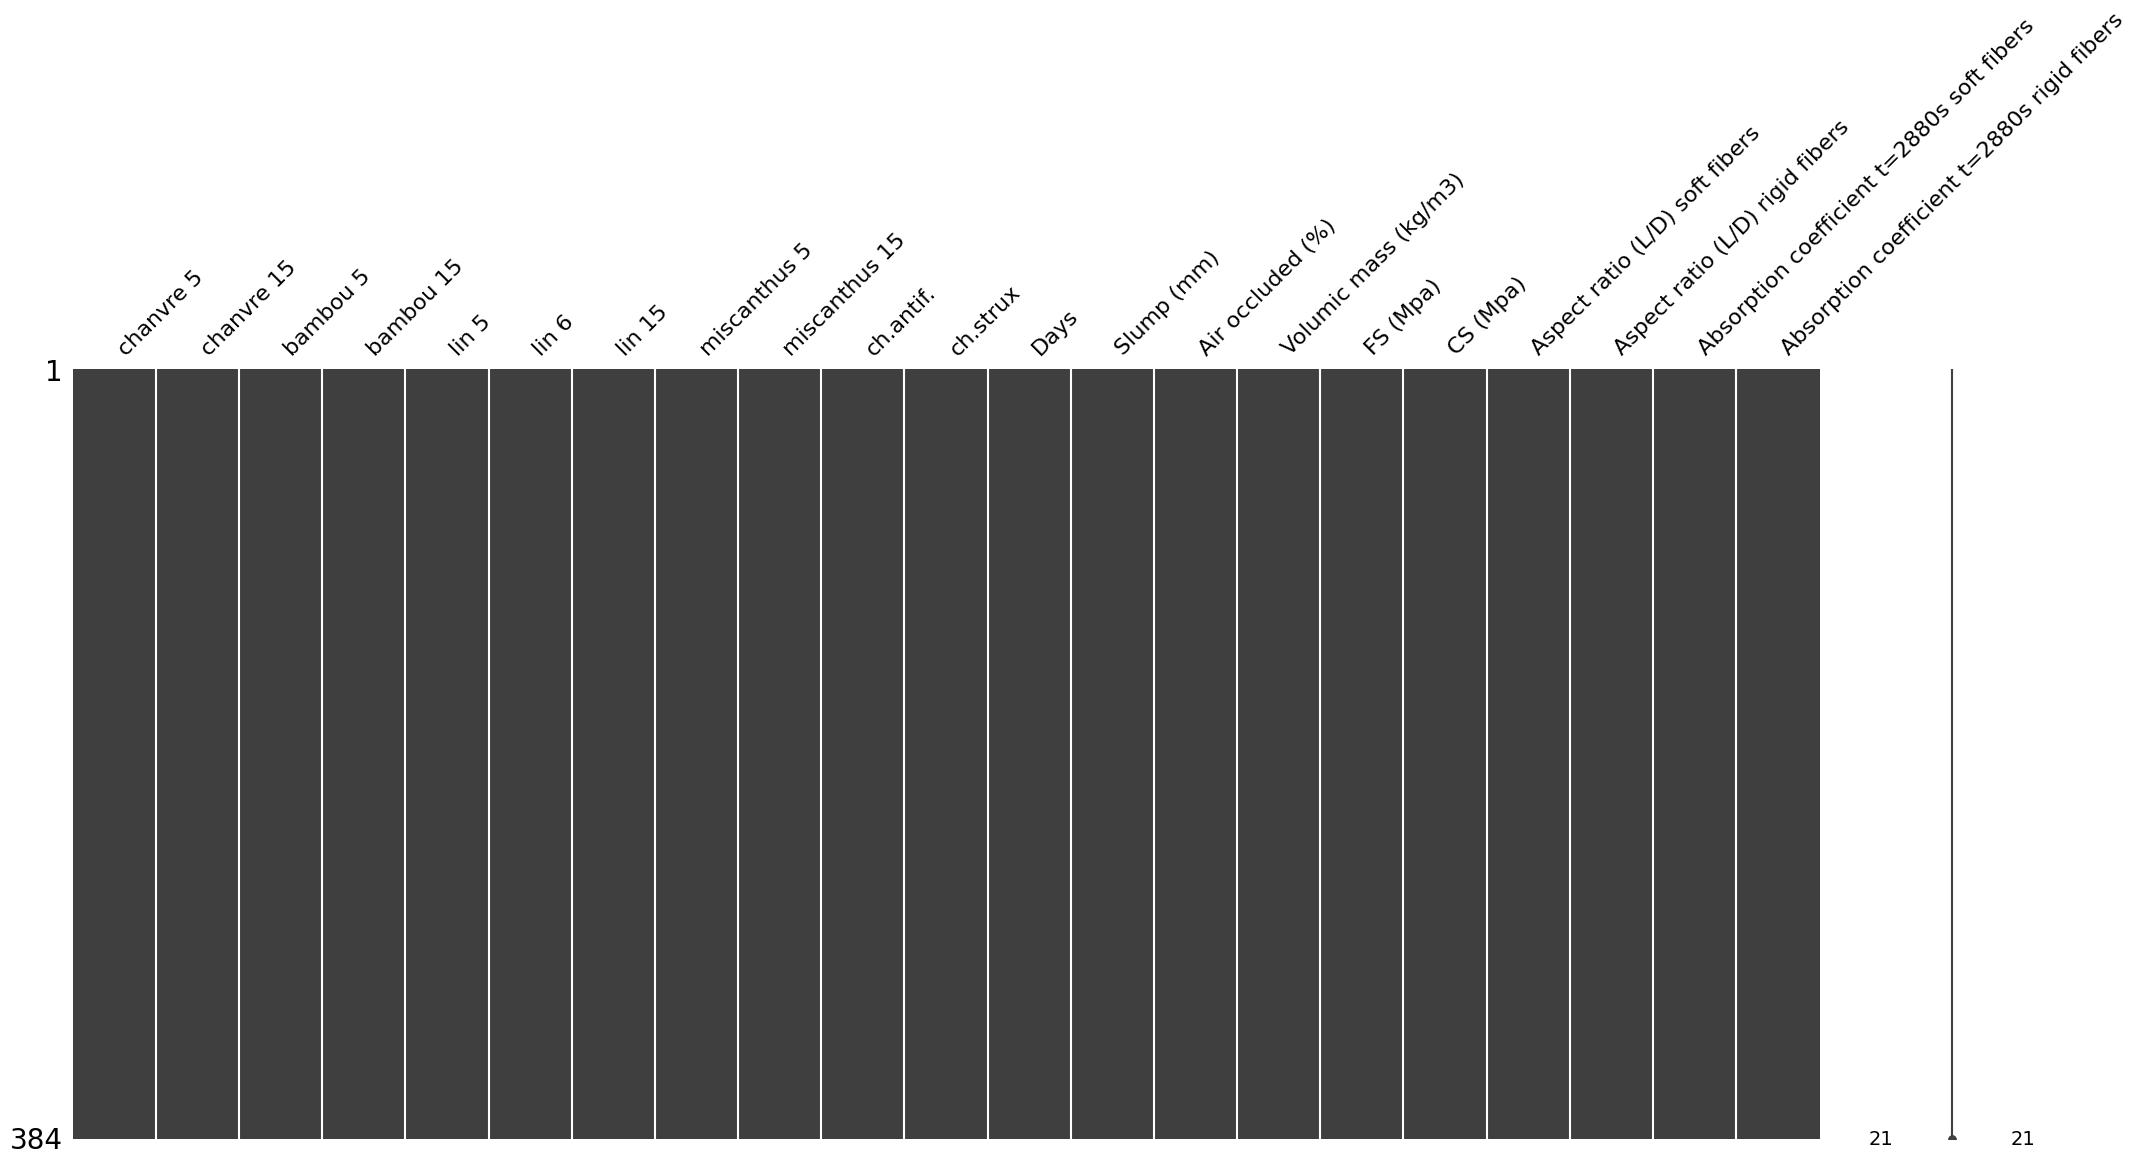

In [6]:
# Visualize missing data
msno.matrix(data)
plt.show()

In [7]:
def show_metric(data, column):
    print("=" * 50)
    print(f"{column:^50}")
    print("=" * 50)
    print(f"{'Données manquantes':<35} {data[column].isna().sum():>10}")
    print(f"{'% manquantes':<35} {round((data[column].isna().sum() / len(data)) * 100, 2):>9}%")
    print(f"{'Données disponibles':<35} {data[column].notna().sum():>10}")
    print(f"Lignes non alignées avec la colonne cible : {len([index for index, row in data.iterrows() if pd.isna(row[column]) and not pd.isna(row['Rc (MPa)'])])}")
    print("=" * 50)

show_metric(data, 'FS (Mpa)')

                     FS (Mpa)                     
Données manquantes                           0
% manquantes                              0.0%
Données disponibles                        384
Lignes non alignées avec la colonne cible : 0


<p style="color: grey;">
The datset has no missing value for flexural strength (FS).
</p>

## 2.3 Categorical Values

<p>On convertit les valeurs catégoriels présentes en integer </p>

In [9]:

categorical_columns = data.select_dtypes(include=['object', 'string']).columns
for column in categorical_columns:
    data[column] = data[column].str.replace(',', '.')
    data[column] = pd.to_numeric(data[column])

In [11]:
data.info() 

<class 'pandas.DataFrame'>
RangeIndex: 384 entries, 0 to 383
Data columns (total 21 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   chanvre 5                                    384 non-null    float64
 1   chanvre 15                                   384 non-null    float64
 2   bambou 5                                     384 non-null    float64
 3   bambou 15                                    384 non-null    float64
 4   lin 5                                        384 non-null    float64
 5   lin 6                                        384 non-null    float64
 6   lin 15                                       384 non-null    float64
 7   miscanthus 5                                 384 non-null    float64
 8   miscanthus 15                                384 non-null    float64
 9   ch.antif.                                    384 non-null    float64
 10  ch.strux     

## 2.2 Outliers

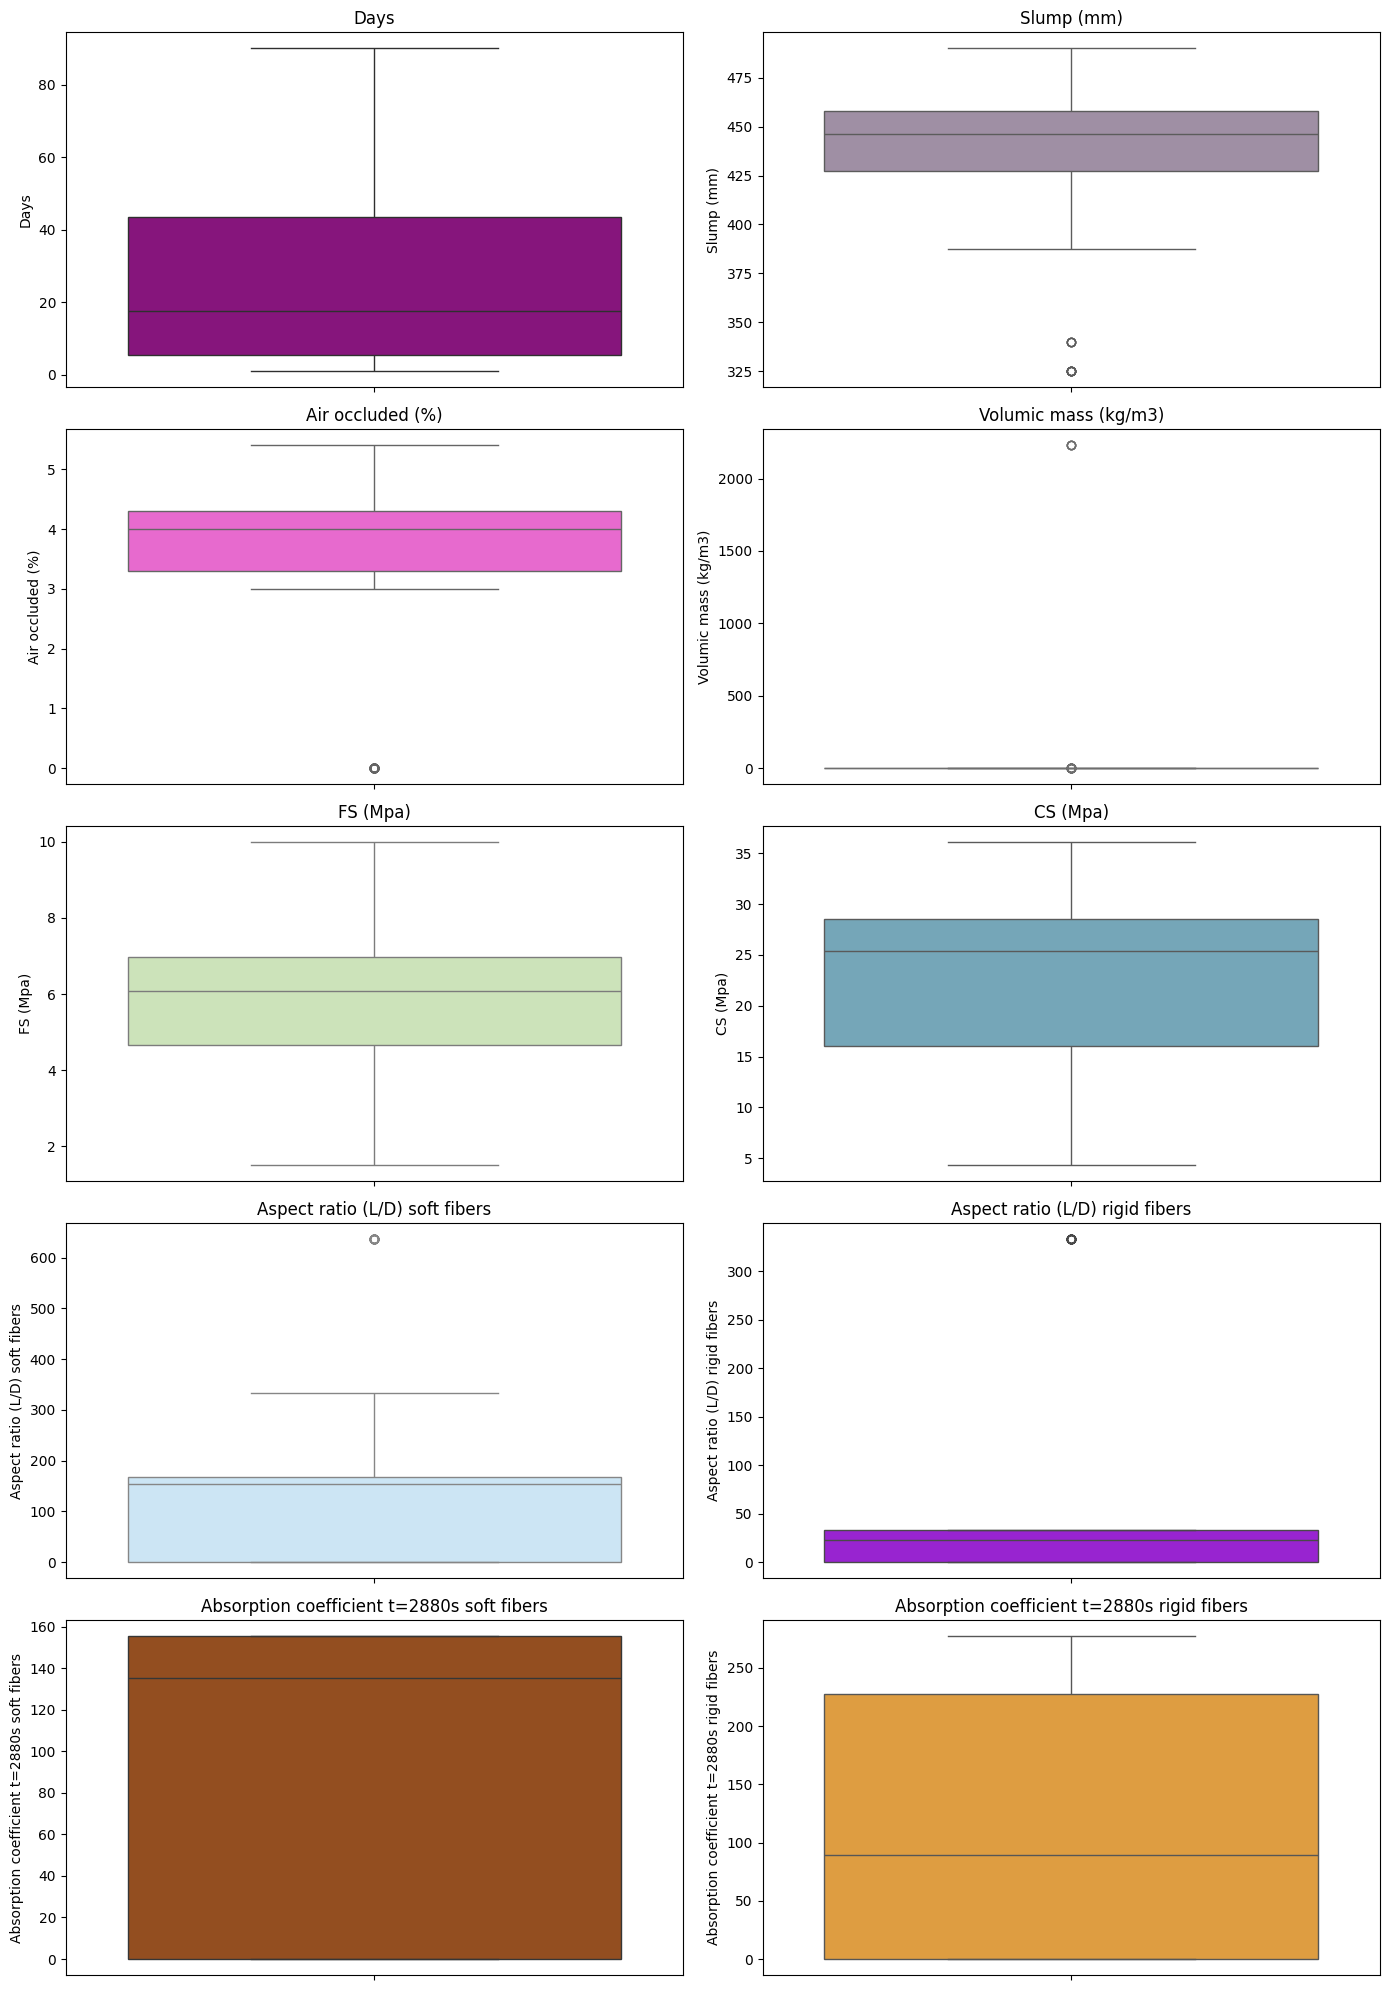

In [13]:
fiber_cols = ['chanvre 5', 'chanvre 15', 'bambou 5', 'bambou 15', 
              'lin 5', 'lin 6', 'lin 15', 'miscanthus 5', 'miscanthus 15',
              'ch.antif.', 'ch.strux']
#ne pas mettre les fiber_cols dans les colonnes numériques pour l'analyse statistique

numerical_columns = data.select_dtypes(include=['float64', 'int64']).columns
numerical_columns = [col for col in numerical_columns if col not in fiber_cols]
n = len(numerical_columns)
cols = 2
rows = (n + 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 4))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    sns.boxplot(y=data[column], ax=axes[i], color=tuple(np.random.rand(3)))
    axes[i].set_title(column)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

<p>On supprime les valeurs aberrantes du dataset</p>

In [ ]:
# def remove_outliers_iqr(df, column, factor=1.5):
#     Q1 = df[column].quantile(0.25)
#     Q3 = df[column].quantile(0.75)
#     IQR = Q3 - Q1
#     lower = Q1 - factor * IQR
#     upper = Q3 + factor * IQR
#     return df[(df[column] >= lower) & (df[column] <= upper)]

# remove_outliers_iqr(data, 'Aspect ratio (L/D) rigid fibers')
# remove_outliers_iqr(data, 'Aspect ratio (L/D) soft fibers')

,chanvre 5,chanvre 15,bambou 5,bambou 15,lin 5,lin 6,lin 15,miscanthus 5,miscanthus 15,ch.antif.,ch.strux,Days,Slump (mm),Air occluded (%),Volumic mass (kg/m3),FS (Mpa),CS (Mpa),Aspect ratio (L/D) soft fibers,Aspect ratio (L/D) rigid fibers,Absorption coefficient t=2880s soft fibers
0,"0,4",0,0,0,0,0,0,0,0,0,0,1,430,3.7,2.2287,2.79,11.36,154,0,135.27
1,0,"0,4",0,0,0,0,0,0,0,0,0,1,455,3.6,2.2198,3.13,10,308,0,135.47
2,0,0,"0,4",0,0,0,0,0,0,0,0,1,450,3.2,2.2366,2.43,8.69,0,17,0.00
3,0,0,0,"0,4",0,0,0,0,0,0,0,1,450,3.3,2.2312,2.82,9.17,0,33,0.00
4,0,0,0,0,"0,4",0,0,0,0,0,0,1,417.5,3.6,2.2117,2.56,7.11,167,0,155.27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
378,0,0,0,0,0,1,0,0,3,0,0,90,447.5,4.4,2.12,6.84,35.21,167,27,155.27
379,"1,2",0,0,"2,8",0,0,0,0,0,0,0,90,440,4.8,2.13,7.32,29.18,154,33,135.27
380,"1,2",0,0,0,0,0,0,0,"2,8",0,0,90,432.5,4.7,2.13,8.29,28.03,154,27,135.27
381,0,0,0,"2,8",0,"1,2",0,0,0,0,0,90,427.5,4.3,2.12,8.3,30.41,167,33,155.27


5. Distri

## 4. CSV Export

In [56]:
#export en csv 
data.to_csv('../data/cleaned_data.csv', index=False)